In [2]:
import torch
import torch.nn as nn
import torchvision

In [3]:
import torch
import torch.nn as nn
import torchvision

# Load pre-trained ResNet18 model
weights = torchvision.models.ResNet18_Weights.DEFAULT
model = torchvision.models.resnet18(weights=weights)

# Define the transformation pipeline matching the model's expected inputs
transforms = weights.transforms()

# Load the OxfordIIITPet dataset with transformations
dataset = torchvision.datasets.OxfordIIITPet(
    root='./data',
    split='trainval',
    transform=transforms,
    download=True
)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 180MB/s]
100%|██████████| 792M/792M [00:43<00:00, 18.1MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 10.8MB/s]


In [4]:
import torch
import torch.nn as nn
from torchvision import models, transforms
# 1. Inisialisasi Model & Ekstraksi Bobot Pretrained
weights = models.ResNet18_Weights.IMAGENET1K_V1
model = models.resnet18(weights=weights)

# 2. Konfigurasi B2: Feature Extraction (Bekukan Backbone)
for param in model.parameters():
  param.requires_grad = False

# Ganti classifier head untuk 10 kelas
num_features = model.fc.in_features
model.fc = nn.Linear(num_features, 10)


In [5]:
# 1. Daftar kelas anjing dan kucing secara eksplisit berdasarkan standar Oxford-IIIT Pet dataset
raw_classes = dataset.classes if hasattr(dataset, 'classes') else []

# Daftar ras kucing (12 ras)
cat_breeds = [
    'Abyssinian', 'Bengal', 'Birman', 'Bombay', 'British Shorthair',
    'Egyptian Mau', 'Maine Coon', 'Persian', 'Ragdoll', 'Russian Blue',
    'Siamese', 'Sphynx'
]

# Pisahkan indeks kelas asli untuk Kucing dan Anjing
cats_indices = [idx for idx, name in enumerate(raw_classes) if name in cat_breeds]
dogs_indices = [idx for idx, name in enumerate(raw_classes) if name not in cat_breeds]

# Ambil 5 ras kucing pertama dan 5 ras anjing pertama
selected_cat_classes = cats_indices[:5]
selected_dog_classes = dogs_indices[:5]
selected_classes = selected_cat_classes + selected_dog_classes

# Buat pemetaan (mapping) dari label lama ke index baru (0-9)
class_mapping = {old_label: new_label for new_label, old_label in enumerate(selected_classes)}

# 2. Filter dataset
target_indices = []
for i, (_, label) in enumerate(dataset):
    if label in class_mapping:
        target_indices.append(i)

# Gunakan Custom Subset untuk memperbarui target/label menjadi 0-9
class_SubsetWithMappedLabels = torch.utils.data.Dataset
class SubsetWithMappedLabels(torch.utils.data.Dataset):
    def __init__(self, dataset, indices, labels_map):
        self.dataset = dataset
        self.indices = indices
        self.labels_map = labels_map
    def __getitem__(self, idx):
        img, label = self.dataset[self.indices[idx]]
        return img, self.labels_map[label]
    def __len__(self):
        return len(self.indices)

filtered_dataset = SubsetWithMappedLabels(dataset, target_indices, class_mapping)

print(f"Terpilih kelas Kucing: {[raw_classes[c] for c in selected_cat_classes]}")
print(f"Terpilih kelas Anjing: {[raw_classes[d] for d in selected_dog_classes]}")
print(f"Total data terpilih (5 kucing & 5 anjing): {len(filtered_dataset)} sampel")

Terpilih kelas Kucing: ['Abyssinian', 'Bengal', 'Birman', 'Bombay', 'British Shorthair']
Terpilih kelas Anjing: ['American Bulldog', 'American Pit Bull Terrier', 'Basset Hound', 'Beagle', 'Boxer']
Total data terpilih (5 kucing & 5 anjing): 996 sampel


In [6]:
import torch
import torch.nn as nn
import torchvision
from torch.utils.data import DataLoader, random_split
import csv
import os

num_classes = 10
num_features = model.fc.in_features
model.fc = nn.Linear(num_features, num_classes)

# Pastikan seluruh backbone tetap beku (Feature Extraction)
for param in model.parameters():
    param.requires_grad = False
for param in model.fc.parameters():
    param.requires_grad = True

# 4. Setup Dataset & DataLoader dari data yang sudah difilter
generator = torch.manual_seed(42)
train_size = int(0.8 * len(filtered_dataset))
val_size = len(filtered_dataset) - train_size
train_set, val_set = random_split(filtered_dataset, [train_size, val_size], generator=generator)

train_loader = DataLoader(train_set, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_set, batch_size=32, shuffle=False, num_workers=2)

# 5. Optimizer dan Loss Function
optimizer = torch.optim.Adam(model.fc.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


In [7]:
import torch
import torch.nn as nn
import torchvision
from torchvision import transforms
from torch.utils.data import DataLoader, random_split
import csv
import matplotlib.pyplot as plt
import pandas as pd

# 1. Definisikan Pipeline Augmentasi Skenario 1 & Skenario 2
# Ambil normalisasi bawaan weights untuk konsistensi
weights_ref = torchvision.models.ResNet18_Weights.IMAGENET1K_V1
standard_transforms = weights_ref.transforms()

# Skenario 1: Tanpa Augmentasi Tambahan (Hanya standard preprocessing dari weights)
transforms_sc1 = standard_transforms

# Skenario 2: Dengan Augmentasi Tambahan
transforms_sc2 = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# 2. Re-load dataset dengan masing-masing transformasi
dataset_sc1 = torchvision.datasets.OxfordIIITPet(
    root='./data', split='trainval', transform=transforms_sc1, download=False
)
dataset_sc2 = torchvision.datasets.OxfordIIITPet(
    root='./data', split='trainval', transform=transforms_sc2, download=False
)

# Memfilter dataset untuk 10 kelas yang sama menggunakan SubsetWithMappedLabels sebelumnya
filtered_sc1 = SubsetWithMappedLabels(dataset_sc1, target_indices, class_mapping)
filtered_sc2 = SubsetWithMappedLabels(dataset_sc2, target_indices, class_mapping)

# Split train & validation set
generator = torch.manual_seed(42)
train_size = int(0.8 * len(filtered_sc1))
val_size = len(filtered_sc1) - train_size

train_set_sc1, val_set_sc1 = random_split(filtered_sc1, [train_size, val_size], generator=generator)
train_set_sc2, val_set_sc2 = random_split(filtered_sc2, [train_size, val_size], generator=generator)

# DataLoader
train_loader_sc1 = DataLoader(train_set_sc1, batch_size=32, shuffle=True, num_workers=2)
val_loader_sc1 = DataLoader(val_set_sc1, batch_size=32, shuffle=False, num_workers=2)

train_loader_sc2 = DataLoader(train_set_sc2, batch_size=32, shuffle=True, num_workers=2)
val_loader_sc2 = DataLoader(val_set_sc2, batch_size=32, shuffle=False, num_workers=2)

In [8]:
import time
import csv
import torch
import torch.nn as nn
import torchvision
from sklearn.metrics import f1_score

def train_evaluate_and_log(name, model, train_loader, val_loader, csv_filename, train_set_len, val_set_len, optimizer, criterion, epochs=3):
    """Fungsi universal untuk melatih, mengevaluasi, mengukur waktu, dan menghitung Macro F1-Score untuk semua skenario."""
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = model.to(device)

    # Setup CSV header
    with open(csv_filename, mode='w', newline='') as f:
        writer = csv.writer(f)
        writer.writerow(["epoch", "train_loss", "train_acc", "train_macro_f1", "val_loss", "val_acc", "val_macro_f1", "epoch_duration_seconds"])

    print(f"=== Memulai Eksperimen: {name} ===")
    for epoch in range(epochs):
        start_time = time.time()

        # --- FASE TRAINING ---
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        all_train_preds, all_train_targets = [], []

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

            all_train_preds.extend(predicted.cpu().numpy())
            all_train_targets.extend(labels.cpu().numpy())

        epoch_duration = time.time() - start_time
        epoch_loss = running_loss / train_set_len
        epoch_acc = 100. * correct / total
        train_f1 = f1_score(all_train_targets, all_train_preds, average='macro')

        # --- FASE VALIDASI ---
        model.eval()
        val_loss, val_correct, val_total = 0.0, 0, 0
        all_val_preds, all_val_targets = [], []

        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)

                val_loss += loss.item() * images.size(0)
                _, predicted = outputs.max(1)
                val_total += labels.size(0)
                val_correct += predicted.eq(labels).sum().item()

                all_val_preds.extend(predicted.cpu().numpy())
                all_val_targets.extend(labels.cpu().numpy())

        val_epoch_loss = val_loss / val_set_len
        val_epoch_acc = 100. * val_correct / val_total
        val_f1 = f1_score(all_val_targets, all_val_preds, average='macro')

        print(f"Epoch [{epoch+1}/{epochs}] - Waktu: {epoch_duration:.2f}s | "
              f"Train Loss: {epoch_loss:.4f}, Acc: {epoch_acc:.2f}%, F1: {train_f1:.4f} | "
              f"Val Loss: {val_epoch_loss:.4f}, Acc: {val_epoch_acc:.2f}%, F1: {val_f1:.4f}")

        # Tulis ke file CSV
        with open(csv_filename, mode='a', newline='') as f:
            writer = csv.writer(f)
            writer.writerow([
                epoch+1,
                f"{epoch_loss:.4f}", f"{epoch_acc:.2f}", f"{train_f1:.4f}",
                f"{val_epoch_loss:.4f}", f"{val_epoch_acc:.2f}", f"{val_f1:.4f}",
                f"{epoch_duration:.2f}"
            ])
    print(f"Selesai! Log disimpan di {csv_filename}\n")

### Kode Pelatihan Bersih Terintegrasi (Tanpa Redundansi)
Di bawah ini adalah kode yang telah disederhanakan dengan menghapus semua fungsi lama yang tidak terpakai, sehingga Anda dapat melatih dan mencatat metrik untuk seluruh konfigurasi model secara bersih.

In [9]:
# Eksekusi seluruh skenario menggunakan fungsi logger universal tunggal
# Menghapus seluruh helper function lama untuk menjaga kekompakan kode

# 1. B1: Scratch
print("Memulai B1...")
model_b1_new = torchvision.models.resnet18(weights=None)
model_b1_new.fc = nn.Linear(model_b1_new.fc.in_features, 10)
optimizer_b1 = torch.optim.Adam(model_b1_new.parameters(), lr=1e-3)
train_evaluate_and_log(
    name="B1 (Scratch)",
    model=model_b1_new,
    train_loader=train_loader_sc1,
    val_loader=val_loader_sc1,
    csv_filename="training_logs_b1_scratch_clean.csv",
    train_set_len=len(train_set_sc1),
    val_set_len=len(val_set_sc1),
    optimizer=optimizer_b1,
    criterion=criterion
)

# 2. B2: Feature Extraction
print("Memulai B2...")
model_b2_new = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1)
model_b2_new.fc = nn.Linear(model_b2_new.fc.in_features, 10)
for param in model_b2_new.parameters():
    param.requires_grad = False
for param in model_b2_new.fc.parameters():
    param.requires_grad = True
optimizer_b2 = torch.optim.Adam(model_b2_new.fc.parameters(), lr=1e-3)
train_evaluate_and_log(
    name="B2 (Feature Extraction)",
    model=model_b2_new,
    train_loader=train_loader_sc1,
    val_loader=val_loader_sc1,
    csv_filename="training_logs_b2_feature_extraction_clean.csv",
    train_set_len=len(train_set_sc1),
    val_set_len=len(val_set_sc1),
    optimizer=optimizer_b2,
    criterion=criterion
)

# 3. B3 Skenario 1 (Fine-Tuning L4 + FC - Tanpa Augmentasi)
print("Memulai B3 Skenario 1...")
model_b3_sc1 = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1)
model_b3_sc1.fc = nn.Linear(model_b3_sc1.fc.in_features, 10)
for param in model_b3_sc1.parameters():
    param.requires_grad = False
for param in model_b3_sc1.layer4.parameters():
    param.requires_grad = True
for param in model_b3_sc1.fc.parameters():
    param.requires_grad = True
optimizer_b3_sc1 = torch.optim.Adam([
    {'params': model_b3_sc1.layer4.parameters(), 'lr': 1e-4},
    {'params': model_b3_sc1.fc.parameters(), 'lr': 1e-3}
])
train_evaluate_and_log(
    name="B3 S1 (Fine-Tuning - No Augment)",
    model=model_b3_sc1,
    train_loader=train_loader_sc1,
    val_loader=val_loader_sc1,
    csv_filename="training_logs_b3_no_augmentation_clean.csv",
    train_set_len=len(train_set_sc1),
    val_set_len=len(val_set_sc1),
    optimizer=optimizer_b3_sc1,
    criterion=criterion
)

# 4. B3 Skenario 2 (Fine-Tuning L4 + FC - Dengan Augmentasi)
print("Memulai B3 Skenario 2...")
model_b3_sc2 = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1)
model_b3_sc2.fc = nn.Linear(model_b3_sc2.fc.in_features, 10)
for param in model_b3_sc2.parameters():
    param.requires_grad = False
for param in model_b3_sc2.layer4.parameters():
    param.requires_grad = True
for param in model_b3_sc2.fc.parameters():
    param.requires_grad = True
optimizer_b3_sc2 = torch.optim.Adam([
    {'params': model_b3_sc2.layer4.parameters(), 'lr': 1e-4},
    {'params': model_b3_sc2.fc.parameters(), 'lr': 1e-3}
])
train_evaluate_and_log(
    name="B3 S2 (Fine-Tuning - With Augment)",
    model=model_b3_sc2,
    train_loader=train_loader_sc2,
    val_loader=val_loader_sc2,
    csv_filename="training_logs_b3_with_augmentation_clean.csv",
    train_set_len=len(train_set_sc2),
    val_set_len=len(val_set_sc2),
    optimizer=optimizer_b3_sc2,
    criterion=criterion
)

Memulai B1...
=== Memulai Eksperimen: B1 (Scratch) ===
Epoch [1/3] - Waktu: 10.31s | Train Loss: 2.3461, Acc: 20.60%, F1: 0.1794 | Val Loss: 8.9529, Acc: 19.50%, F1: 0.1418
Epoch [2/3] - Waktu: 4.32s | Train Loss: 1.9889, Acc: 29.65%, F1: 0.2587 | Val Loss: 2.3836, Acc: 19.00%, F1: 0.1413
Epoch [3/3] - Waktu: 5.69s | Train Loss: 1.8278, Acc: 37.56%, F1: 0.3467 | Val Loss: 2.3666, Acc: 22.50%, F1: 0.2048
Selesai! Log disimpan di training_logs_b1_scratch_clean.csv

Memulai B2...
=== Memulai Eksperimen: B2 (Feature Extraction) ===
Epoch [1/3] - Waktu: 3.98s | Train Loss: 1.9015, Acc: 38.69%, F1: 0.3786 | Val Loss: 1.1616, Acc: 76.50%, F1: 0.7555
Epoch [2/3] - Waktu: 4.68s | Train Loss: 0.9467, Acc: 80.40%, F1: 0.8016 | Val Loss: 0.7306, Acc: 85.00%, F1: 0.8496
Epoch [3/3] - Waktu: 4.17s | Train Loss: 0.6267, Acc: 86.31%, F1: 0.8631 | Val Loss: 0.5022, Acc: 88.50%, F1: 0.8826
Selesai! Log disimpan di training_logs_b2_feature_extraction_clean.csv

Memulai B3 Skenario 1...
=== Memulai Eksper

In [10]:
import torch
import torch.nn as nn
import torchvision
import time

# 1. Load Pretrained MobileNetV3-Small
weights_mn = torchvision.models.MobileNet_V3_Small_Weights.DEFAULT
model_mn = torchvision.models.mobilenet_v3_small(weights=weights_mn)

# 2. Freeze backbone but keep the last classifier and late stages trainable
# For MobileNetV3, the features extraction has multiple stages. We freeze everything first:
for param in model_mn.parameters():
    param.requires_grad = False

# Unfreeze the last block of features (features[12]) and the classifier head
for param in model_mn.features[12].parameters():
    param.requires_grad = True

# Replace classifier with 10 classes
num_features_mn = model_mn.classifier[3].in_features
model_mn.classifier[3] = nn.Linear(num_features_mn, 10)
for param in model_mn.classifier.parameters():
    param.requires_grad = True

# 3. Calculate parameters
total_params = sum(p.numel() for p in model_mn.parameters())
trainable_params = sum(p.numel() for p in model_mn.parameters() if p.requires_grad)
print(f"MobileNetV3-Small -> Total Params: {total_params:,} | Trainable Params: {trainable_params:,}")

# Calculate ResNet18 parameter reference
model_r18 = torchvision.models.resnet18()
r18_total = sum(p.numel() for p in model_r18.parameters())
print(f"ResNet18 (Reference) -> Total Params: {r18_total:,}")

# 4. Setup Optimizer and Run Experiment
optimizer_mn = torch.optim.Adam([
    {'params': model_mn.features[12].parameters(), 'lr': 1e-4},
    {'params': model_mn.classifier.parameters(), 'lr': 1e-3}
])

train_evaluate_and_log(
    name="MobileNetV3-Small (Best Config)",
    model=model_mn,
    train_loader=train_loader_sc1,
    val_loader=val_loader_sc1,
    csv_filename="training_logs_mobilenet_clean.csv",
    train_set_len=len(train_set_sc1),
    val_set_len=len(val_set_sc1),
    optimizer=optimizer_mn,
    criterion=criterion
)

MobileNetV3-Small -> Total Params: 1,528,106 | Trainable Params: 657,546
ResNet18 (Reference) -> Total Params: 11,689,512
=== Memulai Eksperimen: MobileNetV3-Small (Best Config) ===
Epoch [1/3] - Waktu: 4.02s | Train Loss: 1.2884, Acc: 58.79%, F1: 0.5827 | Val Loss: 0.5201, Acc: 79.00%, F1: 0.7937
Epoch [2/3] - Waktu: 5.33s | Train Loss: 0.4006, Acc: 88.57%, F1: 0.8823 | Val Loss: 0.3731, Acc: 84.50%, F1: 0.8496
Epoch [3/3] - Waktu: 3.86s | Train Loss: 0.2887, Acc: 91.33%, F1: 0.9131 | Val Loss: 0.2977, Acc: 88.00%, F1: 0.8834
Selesai! Log disimpan di training_logs_mobilenet_clean.csv



In [11]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load data logs dari file CSV
b1_df = pd.read_csv('training_logs_b1_scratch_clean.csv')
b2_df = pd.read_csv('training_logs_b2_feature_extraction_clean.csv')
b3_sc1_df = pd.read_csv('training_logs_b3_no_augmentation_clean.csv')
b3_sc2_df = pd.read_csv('training_logs_b3_with_augmentation_clean.csv')
mn_df = pd.read_csv('training_logs_mobilenet_clean.csv')

# 2. Fungsi pembantu untuk mengekstrak metrik terbaik
def get_summary_row(df, name, strategy, lr, trainable_params):
    best_epoch_idx = df['val_macro_f1'].idxmax()
    best_row = df.iloc[best_epoch_idx]
    total_duration = df['epoch_duration_seconds'].sum()
    return {
        "Skenario / Model": name,
        "Strategi": strategy,
        "Trainable Params": f"{trainable_params:,}",
        "Learning Rate": lr,
        "Epoch Terbaik": int(best_row['epoch']),
        "Total Waktu (s)": f"{total_duration:.2f}s",
        "Val Accuracy": f"{best_row['val_acc']:.2f}%",
        "Val Macro F1": f"{best_row['val_macro_f1']:.4f}"
    }

summary_data = [
    get_summary_row(b1_df, "B1: ResNet18 (Scratch)", "Train Full dari Nol", "1e-3", 11689512),
    get_summary_row(b2_df, "B2: ResNet18 (Feature Extraction)", "Freeze Backbone, Train FC", "1e-3", 5120),
    get_summary_row(b3_sc1_df, "B3 S1: ResNet18 (Fine-Tuning)", "Train L4 + FC (No Augment)", "1e-4 & 1e-3", 8393856),
    get_summary_row(b3_sc2_df, "B3 S2: ResNet18 (Fine-Tuning)", "Train L4 + FC (With Augment)", "1e-4 & 1e-3", 8393856),
    get_summary_row(mn_df, "B5: MobileNetV3-Small", "Train L12 + FC (No Augment)", "1e-4 & 1e-3", 657546)
]

summary_df = pd.DataFrame(summary_data)
display(summary_df)

,Skenario / Model,Strategi,Trainable Params,Learning Rate,Epoch Terbaik,Total Waktu (s),Val Accuracy,Val Macro F1
0,B1: ResNet18 (Scratch),Train Full dari Nol,"11,689,512",1e-3,3,20.32s,22.50%,0.2048
1,B2: ResNet18 (Feature Extraction),"Freeze Backbone, Train FC","5,120",1e-3,3,12.83s,88.50%,0.8826
2,B3 S1: ResNet18 (Fine-Tuning),Train L4 + FC (No Augment),"8,393,856",1e-4 & 1e-3,2,12.73s,93.50%,0.9315
3,B3 S2: ResNet18 (Fine-Tuning),Train L4 + FC (With Augment),"8,393,856",1e-4 & 1e-3,3,17.73s,89.50%,0.8993
4,B5: MobileNetV3-Small,Train L12 + FC (No Augment),"657,546",1e-4 & 1e-3,3,13.21s,88.00%,0.8834


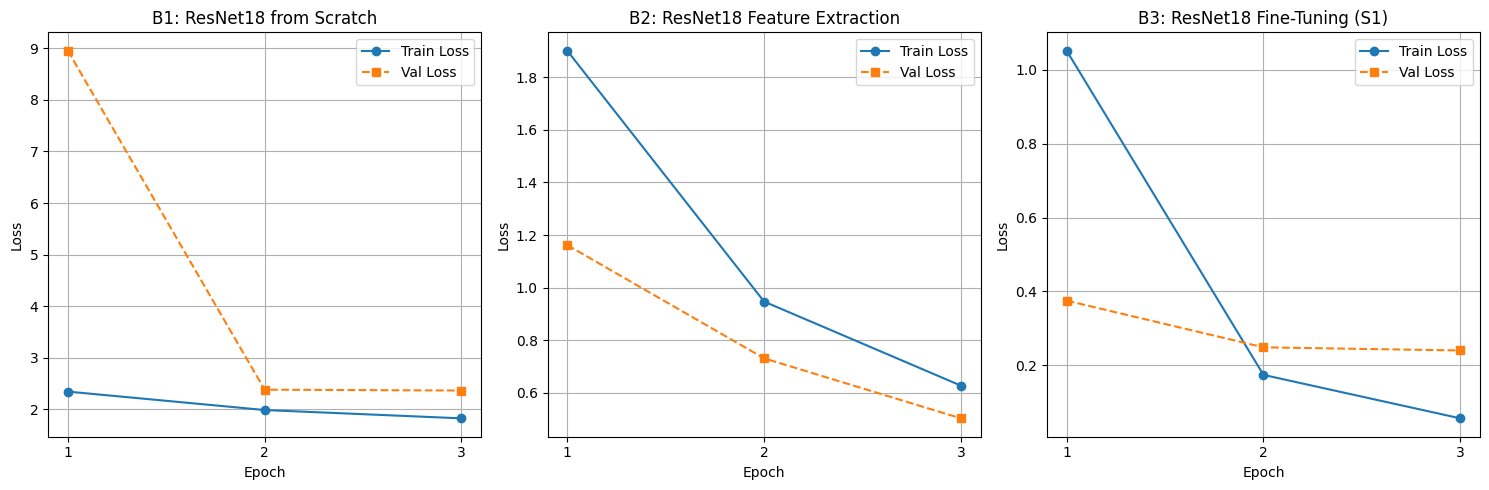

In [12]:
# 3. Plot Training Loss vs Validation Loss untuk B1, B2, dan B3 (S1)
epochs = range(1, 4)
plt.figure(figsize=(15, 5))

# Plot B1
plt.subplot(1, 3, 1)
plt.plot(epochs, b1_df['train_loss'], 'o-', label='Train Loss')
plt.plot(epochs, b1_df['val_loss'], 's--', label='Val Loss')
plt.title('B1: ResNet18 from Scratch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.xticks(epochs)
plt.legend()
plt.grid(True)

# Plot B2
plt.subplot(1, 3, 2)
plt.plot(epochs, b2_df['train_loss'], 'o-', label='Train Loss')
plt.plot(epochs, b2_df['val_loss'], 's--', label='Val Loss')
plt.title('B2: ResNet18 Feature Extraction')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.xticks(epochs)
plt.legend()
plt.grid(True)

# Plot B3 (Scenario 1)
plt.subplot(1, 3, 3)
plt.plot(epochs, b3_sc1_df['train_loss'], 'o-', label='Train Loss')
plt.plot(epochs, b3_sc1_df['val_loss'], 's--', label='Val Loss')
plt.title('B3: ResNet18 Fine-Tuning (S1)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.xticks(epochs)
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

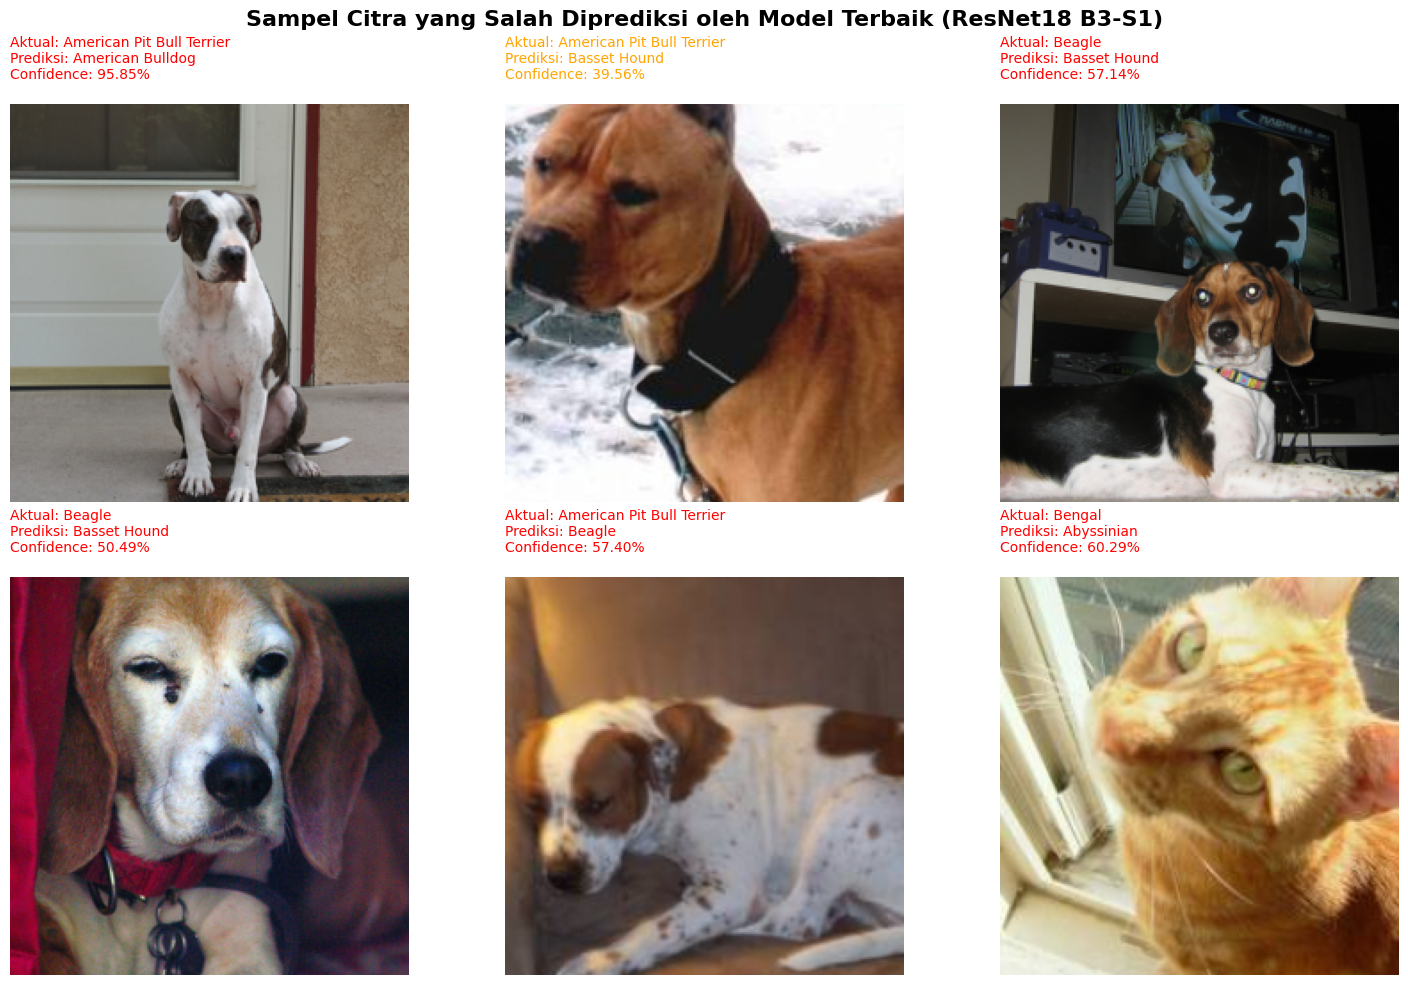

In [15]:
import torch
import torch.nn as nn
import torchvision
import matplotlib.pyplot as plt
import numpy as np

# 1. Pastikan model terbaik (B3 S1) berada pada kondisi evaluasi
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_b3_sc1.eval()

# Balik pemetaan kelas indeks ke nama ras
idx_to_class = {v: raw_classes[k] for k, v in class_mapping.items()}

misclassified_samples = []

# 2. Iterasi dataset validasi untuk mengumpulkan prediksi salah
with torch.no_grad():
    for img_tensor, label in val_set_sc1:
        # Tambahkan dimensi batch
        input_tensor = img_tensor.unsqueeze(0).to(device)
        outputs = model_b3_sc1(input_tensor)
        probabilities = torch.nn.functional.softmax(outputs, dim=1)
        conf, pred = torch.max(probabilities, 1)

        pred_class = pred.item()
        actual_class = label

        if pred_class != actual_class:
            misclassified_samples.append({
                "image": img_tensor,
                "actual": idx_to_class[actual_class],
                "predicted": idx_to_class[pred_class],
                "confidence": conf.item() * 100
            })
            if len(misclassified_samples) >= 6:  # Ambil 6 sampel
                break

# Fungsi helper untuk denormalisasi citra agar bisa di-plot
def denormalize(tensor):
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img = tensor.numpy().transpose((1, 2, 0))
    img = std * img + mean
    img = np.clip(img, 0, 1)
    return img

# 3. Tampilkan gambar yang salah diprediksi
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
fig.suptitle("Sampel Citra yang Salah Diprediksi oleh Model Terbaik (ResNet18 B3-S1)", fontsize=16, fontweight='bold')

# Daftar hipotesis kegagalan umum untuk referensi analisis
hypotheses = [

]

for idx, sample in enumerate(misclassified_samples):
    ax = axes[idx // 3, idx % 3]
    img = denormalize(sample["image"])
    ax.imshow(img)
    ax.axis('off')

    title_text = (f"Aktual: {sample['actual']}\n"
                  f"Prediksi: {sample['predicted']}\n"
                  f"Confidence: {sample['confidence']:.2f}%\n")
    ax.set_title(title_text, fontsize=10, loc='left', color='red' if sample['confidence'] > 50 else 'orange')

plt.tight_layout()
plt.show()

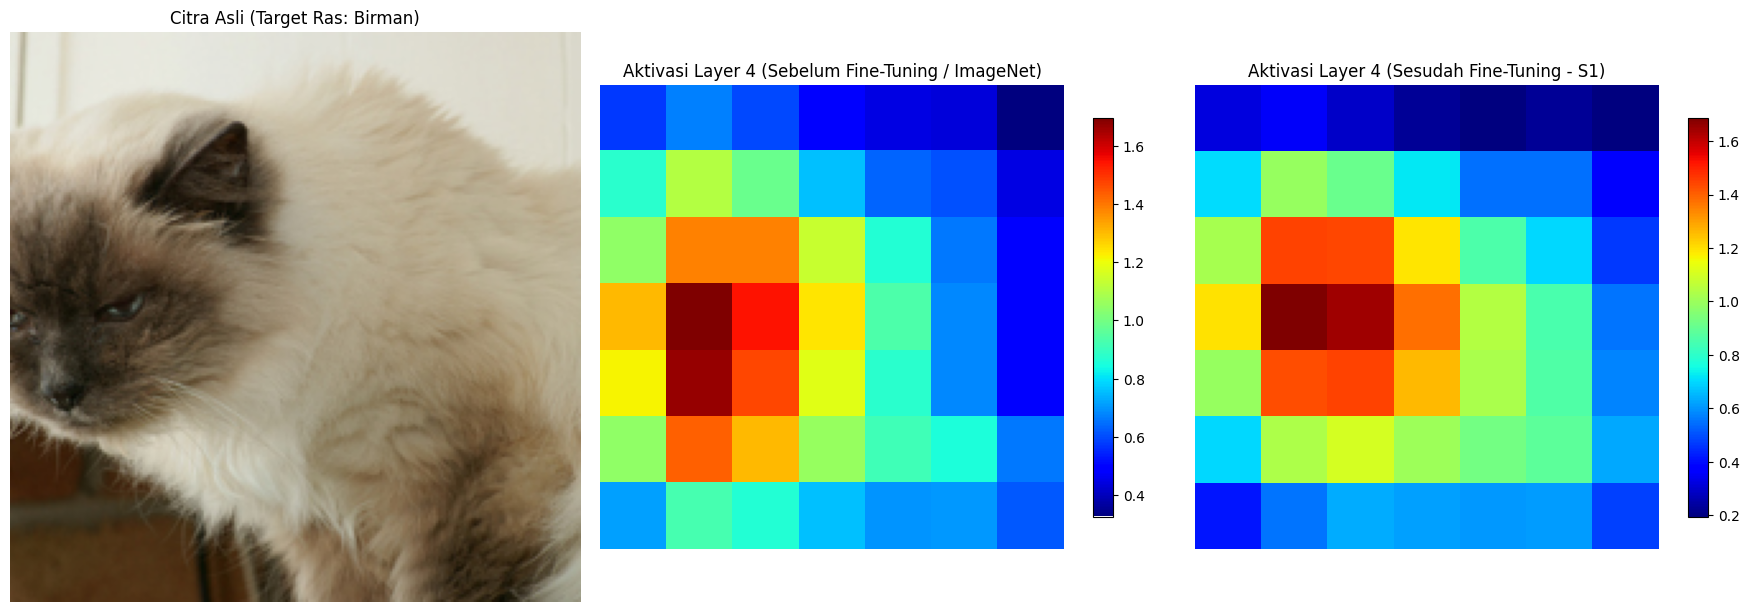

In [16]:
import torch
import torch.nn as nn
import torchvision
import matplotlib.pyplot as plt
import numpy as np

# 1. Load model sebelum fine-tuning (hanya pretrained ImageNet standar)
model_before = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.DEFAULT)
model_before.eval()

# Model sesudah fine-tuning (B3 S1)
model_after = model_b3_sc1
model_after.eval()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_before = model_before.to(device)
model_after = model_after.to(device)

# 2. Ambil 1 sampel citra dari set validasi
img_tensor, label = val_set_sc1[0]  # Sampel pertama
input_batch = img_tensor.unsqueeze(0).to(device)

# Hook untuk menangkap aktivasi dari layer4
activations = {}
def get_activation(name):
    def hook(model, input, output):
        activations[name] = output.detach()
    return hook

# Daftarkan hook pada layer4 untuk kedua model
hook_before = model_before.layer4.register_forward_hook(get_activation('before'))
hook_after = model_after.layer4.register_forward_hook(get_activation('after'))

# Jalankan forward pass
with torch.no_grad():
    _ = model_before(input_batch)
    _ = model_after(input_batch)

# Hapus hook setelah selesai
hook_before.remove()
hook_after.remove()

# 3. Proses feature map (Rata-rata seluruh channel untuk visualisasi 2D)
feature_map_before = activations['before'].squeeze(0).cpu().mean(dim=0).numpy()
feature_map_after = activations['after'].squeeze(0).cpu().mean(dim=0).numpy()

# Fungsi helper denormalisasi citra asli
def denormalize(tensor):
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img = tensor.numpy().transpose((1, 2, 0))
    img = std * img + mean
    return np.clip(img, 0, 1)

# 4. Plot Perbandingan Side-by-Side
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Citra Asli
axes[0].imshow(denormalize(img_tensor))
axes[0].set_title(f"Citra Asli (Target Ras: {idx_to_class[label]})", fontsize=12)
axes[0].axis('off')

# Feature Map Sebelum Fine-Tuning
im1 = axes[1].imshow(feature_map_before, cmap='jet')
axes[1].set_title("Aktivasi Layer 4 (Sebelum Fine-Tuning / ImageNet)", fontsize=12)
axes[1].axis('off')
fig.colorbar(im1, ax=axes[1], shrink=0.7)

# Feature Map Sesudah Fine-Tuning
im2 = axes[2].imshow(feature_map_after, cmap='jet')
axes[2].set_title("Aktivasi Layer 4 (Sesudah Fine-Tuning - S1)", fontsize=12)
axes[2].axis('off')
fig.colorbar(im2, ax=axes[2], shrink=0.7)

plt.tight_layout()
plt.show()

In [17]:
import pandas as pd

# Daftar file log dan label skenarionya
log_files = {
    "B1: ResNet18 (Scratch)": "training_logs_b1_scratch_clean.csv",
    "B2: ResNet18 (Feature Extraction)": "training_logs_b2_feature_extraction_clean.csv",
    "B3 S1: ResNet18 (Fine-Tuning - No Augment)": "training_logs_b3_no_augmentation_clean.csv",
    "B3 S2: ResNet18 (Fine-Tuning - With Augment)": "training_logs_b3_with_augmentation_clean.csv",
    "B5: MobileNetV3-Small": "training_logs_mobilenet_clean.csv"
}

combined_dfs = []

for scenario, file_path in log_files.items():
    try:
        # Membaca file CSV
        df = pd.read_csv(file_path)
        # Menambahkan kolom skenario di awal
        df.insert(0, "scenario", scenario)
        combined_dfs.append(df)
    except FileNotFoundError:
        print(f"Peringatan: Berkas {file_path} tidak ditemukan.")

# Menggabungkan seluruh data
if combined_dfs:
    combined_df = pd.concat(combined_dfs, ignore_index=True)
    # Menyimpan ke satu berkas gabungan
    combined_output_path = "combined_training_logs.csv"
    combined_df.to_csv(combined_output_path, index=False)
    print(f"Berhasil menggabungkan log ke dalam berkas: {combined_output_path}")

    # Menampilkan beberapa baris pertama dari data gabungan
    display(combined_df)
else:
    print("Gagal menggabungkan: Tidak ada file log yang berhasil dibaca.")

Berhasil menggabungkan log ke dalam berkas: combined_training_logs.csv


,scenario,epoch,train_loss,train_acc,train_macro_f1,val_loss,val_acc,val_macro_f1,epoch_duration_seconds
0,B1: ResNet18 (Scratch),1,2.3461,20.60,0.1794,8.9529,19.5,0.1418,10.31
1,B1: ResNet18 (Scratch),2,1.9889,29.65,0.2587,2.3836,19.0,0.1413,4.32
2,B1: ResNet18 (Scratch),3,1.8278,37.56,0.3467,2.3666,22.5,0.2048,5.69
3,B2: ResNet18 (Feature Extraction),1,1.9015,38.69,0.3786,1.1616,76.5,0.7555,3.98
4,B2: ResNet18 (Feature Extraction),2,0.9467,80.40,0.8016,0.7306,85.0,0.8496,4.68
5,B2: ResNet18 (Feature Extraction),3,0.6267,86.31,0.8631,0.5022,88.5,0.8826,4.17
6,B3 S1: ResNet18 (Fine-Tuning - No Augment),1,1.0516,69.47,0.6913,0.3752,89.0,0.8947,3.97
7,B3 S1: ResNet18 (Fine-Tuning - No Augment),2,0.1742,97.36,0.9740,0.2488,93.5,0.9315,4.85
8,B3 S1: ResNet18 (Fine-Tuning - No Augment),3,0.0566,99.87,0.9988,0.2403,91.5,0.9178,3.91
9,B3 S2: ResNet18 (Fine-Tuning - With Augment),1,1.2151,62.56,0.6222,0.3898,89.0,0.8914,6.39
